# Kiểm chứng EASE và các baseline bằng mô phỏng — có biên độ giá ±7% và nhân tố ẩn

Trước khi tin kết quả trên dữ liệu thật (`02_ease_real_data.ipynb`), ta cần biết: (i) cài đặt EASE trong `src/causal_tail.py`
có đúng không; (ii) EASE và các baseline hoạt động thế nào trong điều kiện **giống thị trường HOSE**: lợi suất bị **chặn ±7%**
(EDA, phát hiện 4) và có **nhân tố chung không quan sát được** (thị trường, ngành — EDA, phát hiện 6).
Thiết kế bám theo mục 5.1 của Gnecco và cs. (2021), thêm hai kịch bản kiểm duyệt.

**Thước đo — Structural Intervention Distance (SID, Peters & Bühlmann, 2015).** Với DAG thật $G$ và DAG ước lượng $\hat G$
(thứ tự $\hat\pi$ được đổi thành DAG đầy đủ: $i\to j$ nếu $\hat\pi(i)<\hat\pi(j)$), đếm số cặp $(x,y)$ mà phân phối can thiệp
$p(y\mid do(x))$ suy ra từ $\hat G$ — bằng cách hiệu chỉnh theo tập cha $\mathrm{pa}_{\hat G}(x)$ — là **sai** trong $G$:
$$\mathrm{SID}(G,\hat G) = \frac{1}{p(p-1)}\#\Big\{(x,y),\,x\neq y:\ \mathrm{pa}_{\hat G}(x)\ \text{không phải tập hiệu chỉnh hợp lệ cho } (x,y) \text{ trong } G\Big\}\in[0,1].$$
SID = 0: mọi tác động can thiệp đều suy ra đúng; thứ tự nhân quả đúng luôn cho SID = 0. Với CPDAG (Rank PC), lấy SID trung bình
trên các DAG thuộc lớp tương đương. Khi có biến ẩn, $G$ được thay bằng DAG tổ tiên trên các biến quan sát (mục tiêu (13) của bài báo).
Thước đo phụ: **tỷ lệ xếp ngược** = tỷ lệ cặp (tổ tiên, hậu duệ) bị thứ tự ước lượng đặt sai chiều.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "processing"                      # hình png → report/figure/processing, pdf → report/pdf/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

TABLE_DIR = ROOT / "report" / "table" / FOLDER
RECOMPUTE = False      # True: chạy lại toàn bộ mô phỏng (~5 phút); False: đọc kết quả đã lưu nếu có

## 1. Kiểm tra cài đặt ở mức quần thể (Lemma 1, Ví dụ 1, Mệnh đề 1)

**Tính gì:** với đồ thị "kim cương" $X_1\to X_2,\ X_1\to X_3,\ X_2\to X_4,\ X_3\to X_4$ (Hình 2 của bài báo), tính
$\Gamma$ **quần thể** bằng công thức đóng (6):
$$\Gamma_{jk} = \frac12 + \frac12\,\frac{e_j^\top H_\alpha\, e_{A_{jk}}}{e_j^\top H_\alpha\, e_{\mathrm{An}(j)}},\qquad H=(I-B)^{-1},$$
$H_\alpha$: lũy thừa $\alpha$ từng phần tử; $A_{jk} = \mathrm{An}(j)\cap\mathrm{An}(k)$; $e_C=\sum_{j\in C}e_j$. Sau đó so với ước lượng
thực nghiệm $\hat\Gamma$ từ $n = 10^5$ mẫu (nhiễu Student-t, $\alpha=1{,}5$, $k=\lfloor n^{0,4}\rfloor$) và chạy EASE trên cả hai.

**Kỳ vọng:** $\Gamma_{14}=1>\Gamma_{41}$ (Ví dụ 1); $\Gamma_{23},\Gamma_{32}\in(1/2,1)$ (nguyên nhân chung $X_1$); EASE trả $X_1$ đầu, $X_4$ cuối.

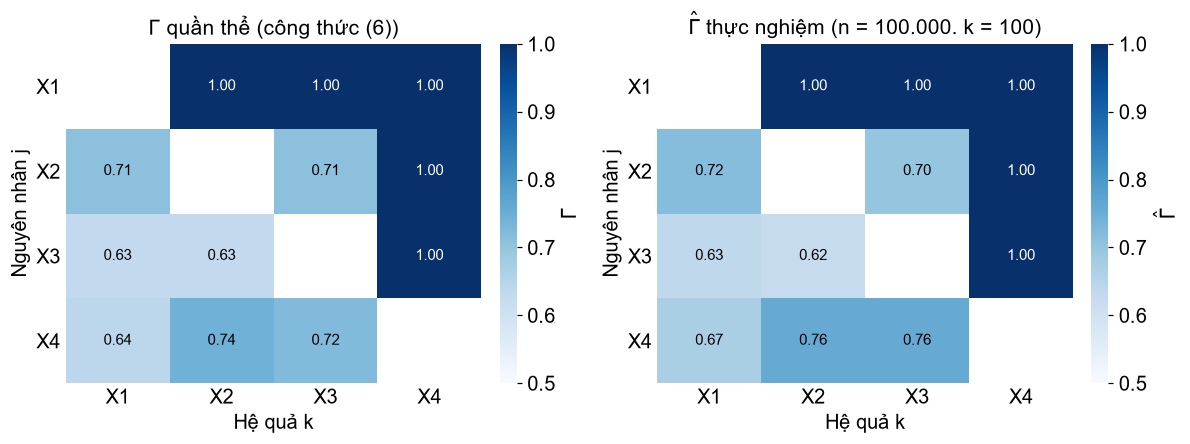

EASE trên Γ quần thể : ['X1', 'X3', 'X2', 'X4']
EASE trên Γ̂ thực nghiệm: ['X1', 'X2', 'X3', 'X4']
Sai lệch tuyệt đối lớn nhất |Γ̂ − Γ| = 0.036


In [2]:
B = np.zeros((4, 4)); B[1, 0], B[2, 0], B[3, 1], B[3, 2] = 0.8, 0.5, 0.7, 0.6       # B[j, h]: cạnh h → j
names = ["X1", "X2", "X3", "X4"]
G_pop = pd.DataFrame(CT.population_gamma(B, alpha=1.5), index=names, columns=names)

rng = np.random.default_rng(0)
n_big = 100_000
eps = rng.standard_t(1.5, (n_big, 4))
X = np.zeros_like(eps)
for j in range(4):                                       # 0,1,2,3 đã là thứ tự tô-pô
    X[:, j] = X @ B[j] + eps[:, j]
G_hat = CT.tail_coef_matrix(pd.DataFrame(X, columns=names), kind="gamma_upper")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
U.make_heatmap(axes[0], G_pop, cmap="Blues", vmin=0.5, vmax=1, cbar_label=r"$\Gamma$", title="Γ quần thể (công thức (6))")
U.make_heatmap(axes[1], G_hat, cmap="Blues", vmin=0.5, vmax=1, cbar_label=r"$\hat\Gamma$",
               title=rf"$\hat\Gamma$ thực nghiệm (n = {n_big:,}, k = {CT.default_k(n_big)})".replace(",", "."))
for ax in axes:
    ax.set_xlabel("Hệ quả k"); ax.set_ylabel("Nguyên nhân j")
U.finalize_figure(fig, "01_population_check", folder=FOLDER); plt.show()
print("EASE trên Γ quần thể :", CT.ease(G_pop))
print("EASE trên Γ̂ thực nghiệm:", CT.ease(G_hat))
print(f"Sai lệch tuyệt đối lớn nhất |Γ̂ − Γ| = {np.nanmax(np.abs(G_hat.values - G_pop.values)):.3f}")

### Phân tích


- Γ quần thể khớp Ví dụ 1 của bài báo: $\Gamma_{14} = 1$, $\Gamma_{41} < 1$; cặp $X_2, X_3$ (chỉ có nguyên nhân chung $X_1$) có cả hai hệ số trong $(1/2, 1)$.
- Với $n = 10^5$, $\hat\Gamma$ lệch khỏi giá trị quần thể tối đa 0,036 — phù hợp tính nhất quán (Định lý 2).
- EASE trên Γ quần thể trả $X_1 \to X_3 \to X_2 \to X_4$, trên $\hat\Gamma$ trả $X_1 \to X_2 \to X_3 \to X_4$: cả hai đều là thứ tự nhân quả đúng
  ($X_2$, $X_3$ không có quan hệ nhân quả nên thứ tự giữa chúng tuỳ ý).

## 2. Thiết kế mô phỏng

Mỗi lần lặp: sinh DAG ngẫu nhiên (Erdős–Rényi, xác suất cạnh $2/(p-1)$ → khoảng $p$ cạnh), hệ số $|\beta|\sim U(0{,}3;\,0{,}9)$ dấu ngẫu nhiên,
nhiễu Student-t bậc tự do $\alpha$ (chỉ số đuôi $\alpha$), rồi
$$X_j = \sum_{h\in\mathrm{pa}(j)}\beta_{jh}X_h + \varepsilon_j .$$

| Kịch bản | Mô tả | Ứng với HOSE |
|---|---|---|
| `linear` | SCM tuyến tính như trên (Setting 1 của bài báo) | — |
| `hidden` | thêm 2 nhân tố ẩn gốc, mỗi nhân tố tác động dương lên từng biến với xác suất 0,5 (Setting 2) | nhân tố thị trường/ngành |
| `censored` | chặn mỗi biến tại phân vị 1,5% và 98,5% | biên độ ±7%: ~1–2% phiên chạm trần/sàn |
| `hidden_censored` | cả hai | gần dữ liệu thật nhất |

Lưới: $n\in\{500, 2000\}$ ($2000\approx$ số phiên thật), $p\in\{5,10,20\}$, $\alpha\in\{1{,}5;\,3\}$ (EDA: chỉ số đuôi lợi suất ~2–3),
20 lần lặp mỗi ô → 960 bộ dữ liệu, cộng ô $n = 2000$, $p = 60$ (**bằng số mã thật**) với 10 lần lặp → 80 bộ; mỗi bộ × 5 phương pháp (chạy song song bằng joblib, seed con độc lập nên kết quả không phụ thuộc số lõi). EASE dùng $\hat\Psi$ (hệ số thực có thể âm), $k=\lfloor n^{0,4}\rfloor$.

In [3]:
sim_path = TABLE_DIR / "01_simulation_results.csv"
if RECOMPUTE or not sim_path.exists():
    sim = CB.simulation_study(ns=(500, 2000), ps=(5, 10, 20), alphas=(1.5, 3.0), reps=20, seed=2026, progress=True, n_jobs=-1)
    sim.to_csv(sim_path, index=False, encoding="utf-8-sig")
else:
    sim = pd.read_csv(sim_path)
# Ô p = 60 (bằng số mã thật sau khi mở rộng): chỉ n = 2000, 10 lần lặp — mỗi bộ dữ liệu mất ~3 phút một lõi
# (Pairwise LiNGAM và Rank PC tăng theo p²), lưu riêng để không phải chạy lại lưới cũ.
sim60_path = TABLE_DIR / "01_simulation_results_p60.csv"
if RECOMPUTE or not sim60_path.exists():
    sim60 = CB.simulation_study(ns=(2000,), ps=(60,), alphas=(1.5, 3.0), reps=10, seed=2060, progress=True, n_jobs=-1)
    sim60.to_csv(sim60_path, index=False, encoding="utf-8-sig")
else:
    sim60 = pd.read_csv(sim60_path)
sim = pd.concat([sim, sim60], ignore_index=True)
print(f"{len(sim):,} dòng = {sim.groupby(['n', 'p', 'alpha', 'setting', 'rep']).ngroups} bộ dữ liệu × "
      f"{sim.method.nunique()} phương pháp")

summary = sim.groupby(["setting", "method"])["SID"].agg(["mean", "sem"]).unstack("method")
order_methods = list(CB.METHODS)
tab = summary["mean"][order_methods].loc[list(CT.SETTINGS)]
U.save_table(tab, "01_sid_by_setting", FOLDER)
tab.style.format("{:.3f}").highlight_min(axis=1, color="#DDF3DE")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed: 10.7min


[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed: 11.9min


[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed: 21.3min


[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed: 26.8min


[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed: 32.5min


... (2 outputs left out)

[Parallel(n_jobs=-1)]: Done  75 out of  80 | elapsed: 53.2min remaining:  3.5min


80 bộ dữ liệu × 5 phương pháp: 3276s
5,200 dòng = 1040 bộ dữ liệu × 5 phương pháp


[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed: 54.6min finished


method,EASE,Pairwise LiNGAM,ICA-LiNGAM,Rank PC,Ngẫu nhiên
setting,,,,,
linear,0.033,0.003,0.011,0.207,0.281
hidden,0.076,0.023,0.078,0.330,0.300
censored,0.032,0.000,0.006,0.226,0.288
hidden_censored,0.087,0.011,0.084,0.348,0.303


## 3. SID theo kịch bản, cỡ mẫu và số biến

**Hình:** mỗi ô là một (chỉ số đuôi $\alpha$, kịch bản); trục hoành là cấu hình $(n,p)$; mỗi đường là một phương pháp
(điểm = SID trung bình 20 lần lặp, thanh = ±1 sai số chuẩn). Thấp hơn là tốt hơn; đường "Ngẫu nhiên" là mức nền.

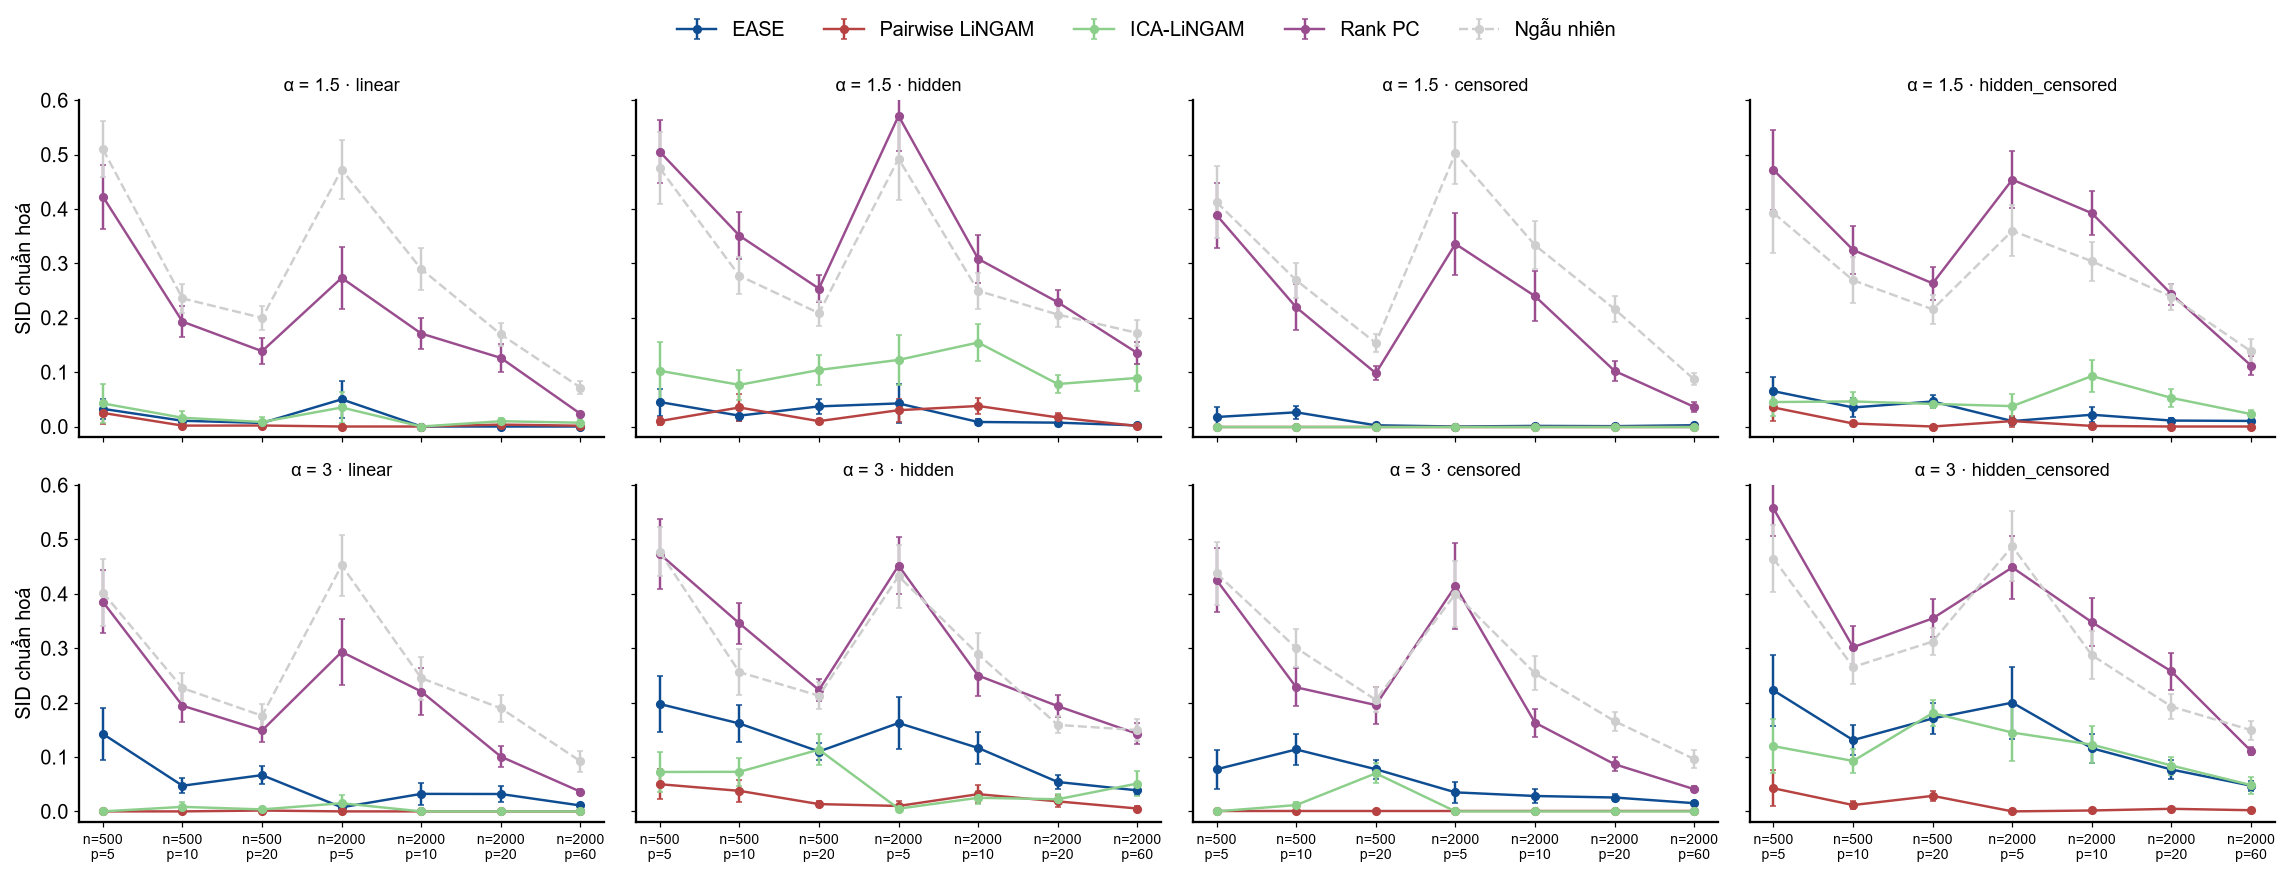

method      EASE  Pairwise LiNGAM  ICA-LiNGAM  Rank PC  Ngẫu nhiên
alpha n                                                           
1.500 500  0.029            0.010       0.040    0.303       0.301
      2000 0.011            0.007       0.046    0.257       0.291
3.000 500  0.127            0.015       0.062    0.319       0.311
      2000 0.067            0.005       0.034    0.242       0.271

In [4]:
configs = [(500, 5), (500, 10), (500, 20), (2000, 5), (2000, 10), (2000, 20), (2000, 60)]
xt = [f"n={n}\np={p}" for n, p in configs]
fig, axes = plt.subplots(2, 4, figsize=(21, 7.5), sharey=True, sharex=True)
for r_i, a in enumerate((1.5, 3.0)):
    for c_i, st in enumerate(CT.SETTINGS):
        ax = axes[r_i, c_i]
        d = sim[(sim.alpha == a) & (sim.setting == st)]
        for m in order_methods:
            g = d[d.method == m].groupby(["n", "p"])["SID"].agg(["mean", "sem"]).reindex(configs)
            ax.errorbar(range(len(configs)), g["mean"], yerr=g["sem"], color=METHOD_COLORS[m], marker="o", ms=5, lw=1.6,
                        capsize=2, label=m, ls="--" if m == "Ngẫu nhiên" else "-")
        ax.set_title(f"α = {a:g} · {st}", fontsize=12)
        ax.set_xticks(range(len(configs)), xt, fontsize=9)
        ax.set_ylim(-0.02, 0.6)
    axes[r_i, 0].set_ylabel("SID chuẩn hoá")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.07))
U.finalize_figure(fig, "01_simulation_sid", folder=FOLDER); plt.show()

by_alpha_n = sim.groupby(["alpha", "n", "method"])["SID"].mean().unstack()[order_methods]
by_alpha_n

### Phân tích

- **Thứ hạng chung giống bài báo:** Pairwise LiNGAM tốt nhất (SID 0,005–0,015), rồi EASE và ICA-LiNGAM; Rank PC chỉ nhỉnh hơn ngẫu nhiên khi không có nhân tố ẩn
  và **kém hơn ngẫu nhiên** khi có (kịch bản `hidden_censored`: 0,348 so với 0,303).
- **EASE mạnh nhất khi đuôi rất dày** ($\alpha = 1{,}5$): SID 0,029 ($n = 500$) và 0,011 ($n = 2000$) — tốt hơn ICA-LiNGAM (0,040–0,046). Khi $\alpha = 3$ (gần
  lợi suất cổ phiếu) EASE kém đi: 0,127 và 0,067, kém ICA-LiNGAM (0,062 và 0,034).
- **Kịch bản gần dữ liệu thật nhất (`hidden_censored`, $\alpha = 3$, $n = 2000$):** với $p = 20$: EASE 0,077, ICA-LiNGAM 0,084, ngẫu nhiên 0,193;
  với **$p = 60$ (bằng số mã thật): EASE 0,047, ICA-LiNGAM 0,048, Pairwise LiNGAM 0,002, Rank PC 0,111, ngẫu nhiên 0,149**.
  SID chuẩn hoá giảm theo $p$ vì DAG thưa hơn (≈ $p$ cạnh trên $p(p-1)$ cặp), nên cần so với mức ngẫu nhiên: EASE đạt 40% mức ngẫu nhiên ở $p = 20$ và **32%** ở $p = 60$ —
  tức **nhiều mã hơn không làm EASE kém đi**, ngược lại tương đối tốt hơn.
- LiNGAM được lợi vì dữ liệu mô phỏng tuyến tính trên **toàn** phân phối; EASE chỉ dùng $2k$ điểm cực trị.

## 4. Ảnh hưởng riêng của kiểm duyệt ±7% và nhân tố ẩn

**Tính gì:** chênh lệch SID trung bình giữa kịch bản có và không có từng yếu tố, giữ nguyên $(n,p,\alpha)$:
$\Delta_{\text{kiểm duyệt}} = \overline{\mathrm{SID}}_{\texttt{censored}} - \overline{\mathrm{SID}}_{\texttt{linear}}$ và
$\Delta_{\text{ẩn}} = \overline{\mathrm{SID}}_{\texttt{hidden}} - \overline{\mathrm{SID}}_{\texttt{linear}}$. Đồng thời xem tỷ lệ xếp ngược
(chỉ cho phương pháp trả thứ tự).

In [5]:
m_ = sim.groupby(["setting", "method"])["SID"].mean().unstack()[order_methods]
effects = pd.DataFrame({"Δ kiểm duyệt": m_.loc["censored"] - m_.loc["linear"],
                        "Δ nhân tố ẩn": m_.loc["hidden"] - m_.loc["linear"],
                        "Δ cả hai": m_.loc["hidden_censored"] - m_.loc["linear"]})
rev = sim.groupby(["alpha", "setting", "method"])["sai_thu_tu"].mean().unstack()[
    [m for m in order_methods if m != "Rank PC"]]
U.save_table(effects, "01_effect_censoring_hidden", FOLDER); U.save_table(rev, "01_reversal_rate", FOLDER)
display(effects.style.format("{:+.3f}"))
rev

,Δ kiểm duyệt,Δ nhân tố ẩn,Δ cả hai
method,,,
EASE,-0.001,+0.042,+0.054
Pairwise LiNGAM,-0.003,+0.021,+0.008
ICA-LiNGAM,-0.005,+0.068,+0.073
Rank PC,+0.018,+0.123,+0.141
Ngẫu nhiên,+0.007,+0.019,+0.022


method                 EASE  Pairwise LiNGAM  ICA-LiNGAM  Ngẫu nhiên
alpha setting                                                       
1.500 censored        0.010            0.000       0.000       0.498
      hidden          0.036            0.029       0.163       0.492
      hidden_censored 0.039            0.006       0.074       0.486
      linear          0.016            0.005       0.023       0.509
3.000 censored        0.088            0.000       0.026       0.485
      hidden          0.185            0.028       0.090       0.489
      hidden_censored 0.194            0.018       0.177       0.505
      linear          0.075            0.000       0.005       0.489

### Phân tích

- **Kiểm duyệt gần như không ảnh hưởng** tới EASE (Δ = −0,001) và hai LiNGAM (−0,003, −0,005). EASE chỉ cần biết "phiên nào cực trị" và **hạng** của biến hệ quả —
  thông tin còn nguyên sau khi chặn. Lưu ý mức kiểm duyệt mô phỏng (1,5% mỗi đuôi) thấp hơn dữ liệu 60 mã (trung vị ~2% phiên chạm mỗi biên, cao nhất 4,6%);
  với $k$ = 21 phiên/đuôi trên ~2.100 phiên (1%), mức chặn 2% vẫn bao trọn đuôi mà EASE dùng nên kết luận "chặn không làm lệch thứ tự" vẫn áp dụng.
- **Nhân tố ẩn mới là nguồn sai số chính:** Δ = +0,042 (EASE), +0,068 (ICA-LiNGAM), +0,123 (Rank PC). Tỷ lệ xếp ngược của EASE ở $\alpha = 3$ tăng từ 0,08 lên
  0,19 khi có nhân tố ẩn — gần 1/5 cặp tổ tiên–hậu duệ bị xếp ngược.

## 5. Chọn số quan sát đuôi $k$ (tái hiện Hình 3 của bài báo, thêm kịch bản giống HOSE)

**Tính gì:** SID của EASE với $k=\lfloor n^\nu\rfloor$, $\nu\in[0{,}2;\,0{,}7]$, $n=2000$, $p=5$, 30 lần lặp, cho
$\alpha\in\{1{,}5;3\}$ × kịch bản {`linear`, `hidden_censored`}. Câu hỏi: $\nu=0{,}4$ của bài báo có còn hợp lý khi dữ liệu bị chặn
và có nhân tố ẩn — đúng cấu hình dùng ở notebook 02?

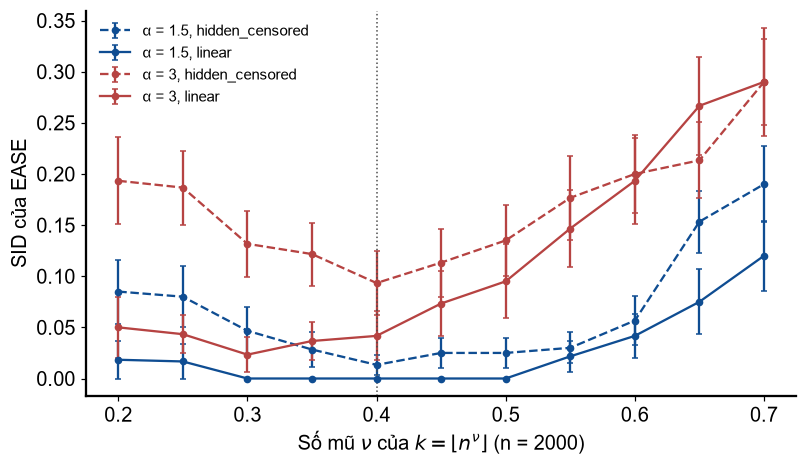

ν tốt nhất theo cấu hình: {(1.5, 'hidden_censored'): 0.4, (1.5, 'linear'): 0.3, (3.0, 'hidden_censored'): 0.4, (3.0, 'linear'): 0.3}


In [6]:
k_path = TABLE_DIR / "01_k_sensitivity_sim.csv"
nus = np.round(np.arange(0.20, 0.701, 0.05), 2)
if RECOMPUTE or not k_path.exists():
    rng = np.random.default_rng(7)
    rows = []
    for a in (1.5, 3.0):
        for st in ("linear", "hidden_censored"):
            for rep in range(30):
                s_ = CT.simulate_scm(2000, 5, a, st, rng)
                truth = CT.observed_ancestral_dag(s_["adj"], s_["observed"])
                for nu in nus:
                    o = CB.run_ease(s_["X"], k=CT.default_k(2000, nu))["order"]
                    rows.append({"alpha": a, "setting": st, "rep": rep, "nu": nu,
                                 "SID": CT.sid(truth, CT.order_to_adjacency(o))})
    ksim = pd.DataFrame(rows); ksim.to_csv(k_path, index=False, encoding="utf-8-sig")
else:
    ksim = pd.read_csv(k_path)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
styles = {"linear": "-", "hidden_censored": "--"}
acol = {1.5: PAL["blue_main"], 3.0: PAL["red_strong"]}
for (a, st), d in ksim.groupby(["alpha", "setting"]):
    g = d.groupby("nu")["SID"].agg(["mean", "sem"])
    ax.errorbar(g.index, g["mean"], yerr=g["sem"], color=acol[a], ls=styles[st], marker="o", ms=4, capsize=2,
                label=f"α = {a:g}, {st}")
ax.axvline(0.4, color=PAL["gray_dark"], ls=":", lw=1)
ax.set_xlabel(r"Số mũ $\nu$ của $k=\lfloor n^{\nu}\rfloor$ (n = 2000)"); ax.set_ylabel("SID của EASE")
ax.legend(fontsize=10)
U.finalize_figure(fig, "01_k_sensitivity_sim", folder=FOLDER); plt.show()
best = ksim.groupby(["alpha", "setting", "nu"])["SID"].mean().groupby(["alpha", "setting"]).idxmin().map(lambda t: t[-1])
print("ν tốt nhất theo cấu hình:", best.to_dict())

### Phân tích


- Không có biến ẩn/kiểm duyệt, $\nu$ tốt nhất là 0,30; trong kịch bản giống HOSE (`hidden_censored`) là **0,40** — đúng giá trị bài báo khuyến nghị,
  nên Processing giữ $k = \lfloor n^{0,4}\rfloor$. (Calibration 01 chọn lại $\nu$ cho dữ liệu đã khử nhân tố.)
- $\nu \ge 0{,}6$ làm SID tăng mạnh (đuôi lẫn phần thân, nơi nhân tố chung chiếm ưu thế); $\nu \le 0{,}25$ thì phương sai lớn.

## 6. Kết luận

1. Cài đặt EASE, hệ số Γ/Ψ và SID khớp lý thuyết (Lemma 1, Ví dụ 1, Mệnh đề 1) và tái hiện thứ hạng các phương pháp của bài báo, kể cả với $p = 60$ bằng số mã thật.
2. **Biên độ ±7% không làm lệch EASE**; nhân tố ẩn và đuôi không quá dày ($\alpha \approx 3$) là hai điểm yếu (SID 0,047 so với 0,149 của ngẫu nhiên ở cấu hình giống thị trường, $p = 60$).
3. Giữ $k = \lfloor n^{0,4}\rfloor$ cho Processing; Validation và Calibration kiểm tra lại lựa chọn này.